# Librerias y constantes

In [111]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, solve_ivp

OMEGA_Mh2 = 0.1323
OMEGA_LAMBDAh2 = 0.3577

# Item $(b)$

Resuelvo numéricamente la integral

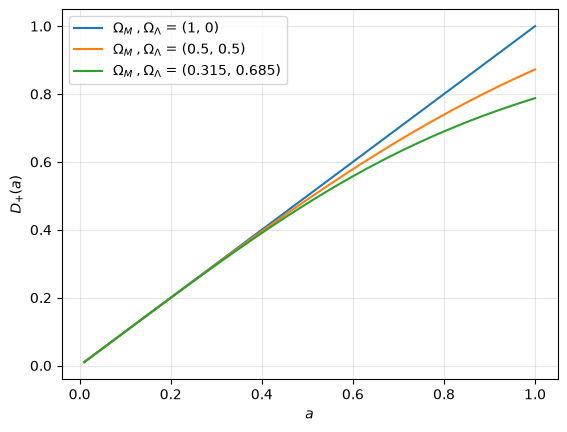

In [ ]:
E = lambda a, omega_m, omega_l: np.sqrt(omega_m*a**(-3) + omega_l)

def D(a, omega_m, omega_l):
    integrando = lambda a: 1/(a*E(a, omega_m, omega_l))**3

    resultados_int = np.array([quad(integrando, 0, _)[0] for _ in list(a)])
    return resultados_int * E(a, omega_m, omega_l) * 5 * omega_m / 2

a_s = np.logspace(-2, 0, 10_000)

# fig, axs = plt.subplots(1, 2, figsize = (14, 6))
fig, axs = plt.subplots()

OMS = [1, .5, .315]
OMLS = [0, .5, .685]

for (OM, OL) in zip(OMS, OMLS):
    axs.plot(a_s, D(a_s, OM, OL), label = r'$\Omega_M \;, \Omega_\Lambda$ = ' + f'({OM}, {OL})')
    axs.set(xlabel = r'$a$', ylabel = r'$D_{+}(a)$')
    axs.grid(alpha = .3)
    axs.legend()

    # axs[1].plot(a_s, D(a_s, OM, OL), label = r'$\Omega_M \;, \Omega_\Lambda$ = ' + f'({OM}, {OL})')
    # axs[1].set(xlabel = r'$a$', ylabel = r'$D_{+}(a)$',
    #         yscale = 'log')
    # axs[1].grid(alpha = .3), axs[1].legend()

fig.savefig('D_mas.png', bbox_inches = 'tight')


Resuelvo numéricamente la ecuación, para esto tengo que convertir mi ecuación de segundo orden en dos ecuaciones de primer orden:
$$
\begin{cases}
D' = \tilde{D} \\
\tilde{D}' = \bigg( \frac{3\Omega_m}{2E^2(a) a^4} - \frac{3}{a}\bigg) \tilde{D} + \frac{3\Omega_m}{2E^2(a)a^4}D
\end{cases}
$$

In [113]:
# Me defino el sistema de ecuaciones de orden 1
def sistema(a, estados, OM_ = OMEGA_Mh2, OL_ = OMEGA_LAMBDAh2):
    D, Dmoño = estados

    Dmoño_prima = (
        ( (3*OM_ / (2 * E(a, OM_, OL_)**2 * a**4)) - (3/a) )*Dmoño + 
        (3*OM_ / (2 * E(a, OM_, OL_)**2 * a**5)) * D
    )

    return [Dmoño, Dmoño_prima]

# Me defino las condiciones iniciales
y0 = [a_s[0], 1] # --> D->0 cuando a->0 y Como D-> a cuando a->0 => D'-> 1 cuando a->0

sol = solve_ivp(sistema, [a_s[0], a_s[-1]], y0, dense_output=True)

Ahora grafico las soluciones comparandolas con las integrales

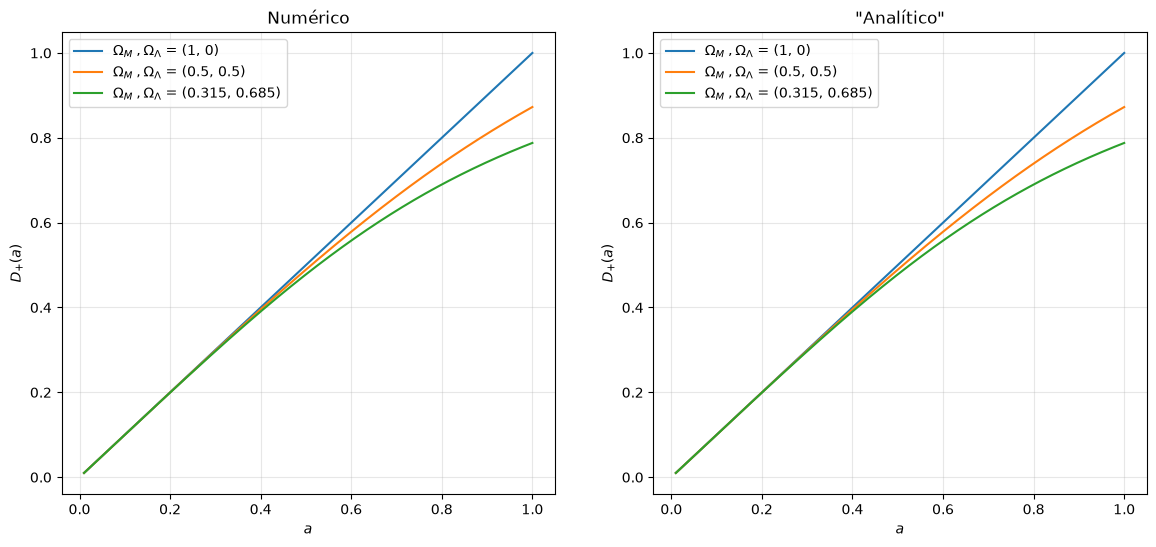

In [114]:
fig, axs = plt.subplots(1, 2, figsize = (14, 6))
for (OM, OL) in zip(OMS, OMLS):
    resolver = lambda a, estados: sistema(a, estados, OM_ = OM, OL_ = OL)
    sol = solve_ivp(resolver, [a_s[0], a_s[-1]], y0, dense_output=True)


    axs[0].plot(a_s, sol.sol(a_s)[0] , label = r'$\Omega_M \;, \Omega_\Lambda$ = ' + f'({OM}, {OL})')
    axs[0].set(xlabel = r'$a$', ylabel = r'$D_{+}(a)$', title = 'Numérico')
    axs[0].grid(alpha = .3)
    axs[0].legend()
    
    axs[1].plot(a_s, D(a_s, OM, OL), label = r'$\Omega_M \;, \Omega_\Lambda$ = ' + f'({OM}, {OL})')
    axs[1].set(xlabel = r'$a$', ylabel = r'$D_{+}(a)$', title = '"Analítico"')
    axs[1].grid(alpha = .3)
    axs[1].legend()

fig.savefig('Comparacion numericas vs analitica.png', bbox_inches = 'tight')

Finalmente grafico $D_+ / a$:

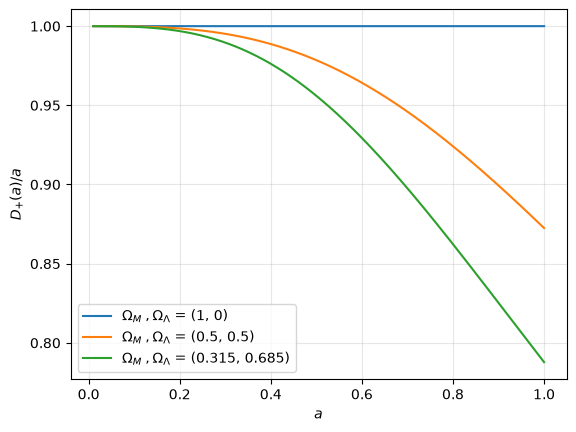

In [116]:
fig, axs = plt.subplots()
for (OM, OL) in zip(OMS, OMLS):
    axs.plot(a_s, D(a_s, OM, OL)/a_s, label = r'$\Omega_M \;, \Omega_\Lambda$ = ' + f'({OM}, {OL})')
    axs.set(xlabel = r'$a$', ylabel = r'$D_{+}(a)/a$')
    axs.grid(alpha = .3)
    axs.legend()

fig.savefig('d sobre a.png', bbox_inches = 'tight')